In [1]:
import sys
sys.path.append('../code')
from hnn_optimization import add_bursty_opt_drives, set_params_bursty_opt_drives

import numpy as np
import matplotlib.pyplot as plt
from hnn_core.batch_simulate import BatchSimulate
from hnn_core import neymotin_2020_model, simulate_dipole
from scipy.signal import butter, sosfiltfilt

# spectral events toolbox
sys.path.append('../externals/SpectralEvents')
import spectralevents as se


--No graphics will be displayed.


In [2]:
tstop = 2500
dt = 0.5
n_prox = 1
n_dist = 1

net = neymotin_2020_model()
constraints, initial_params = add_bursty_opt_drives(net, tstop=tstop, n_prox=n_prox, n_dist=n_dist)

In [3]:
n_samples = 50
bounds = np.array(list(constraints.values()))

rng = np.random.default_rng(seed=129)
theta_dict = {name: rng.uniform(bounds[idx, 0], bounds[idx, 1], size=(n_samples,)) for idx, name in enumerate(constraints.keys())} # random parameter sets 

In [4]:
batch_simulation = BatchSimulate(net=net,
                                set_params=set_params_bursty_opt_drives,
                                save_outputs=False,
                                save_dpl=True,
                                tstop=tstop,
                                dt=dt,
                                clear_cache=False)

res = batch_simulation.run(theta_dict,
                        n_jobs=16,      # had to reduce the number of jobs, reduced memory/# of cores 
                        combinations=False,
                        backend='loky',
                        verbose=False)
                        

--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
/oscar/home/zabebe/jones_lab/tdbrain_bycycle/.pixi/envs/default/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
--No graphics will be displayed.
--No graphics will be displayed.


In [5]:
def gather_sims(res):
    sim_list = []
    for sim_batch in res['simulated_data']:
        for sim in sim_batch:
            data = sim['dpl'][0].copy().data['agg']
            sim_list.append(data)
    sim_array = np.stack(sim_list)
    return sim_array

In [6]:
dpl = gather_sims(res) # built by pulling each signal out of res, dpl array of numbers sitting in memory 

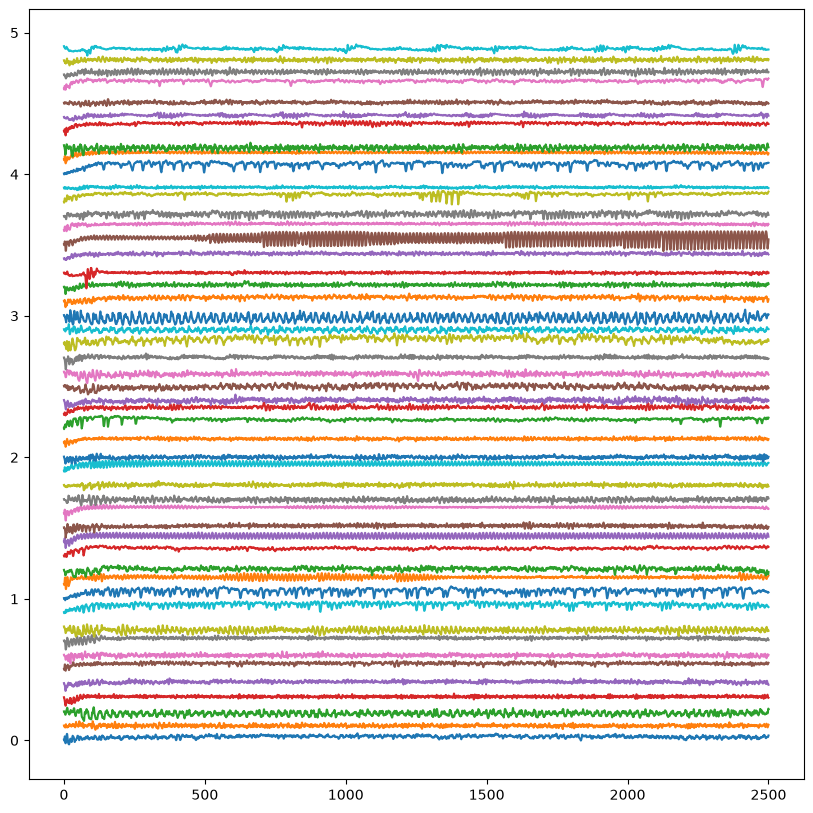

In [7]:
times = np.linspace(0, tstop, dpl.shape[1])
offset = np.arange(0, 50).reshape(1, -1) * 1e-1

plt.figure(figsize=(10, 10))
_ = plt.plot(times, dpl[:50,:].T + offset) # offset so the plots don't overlap 

In [8]:
import numpy as np
import pandas as pd
import mne

from neurodsp.filt import filter_signal
from neurodsp.plts import plot_time_series
from neurodsp.sim import sim_combined

from bycycle import Bycycle
from bycycle.cyclepoints import find_extrema, find_zerox
from bycycle.cyclepoints.zerox import find_flank_zerox
from bycycle.plts import plot_cyclepoints_array
from bycycle.utils.download import load_bycycle_data
from bycycle.plts import plot_feature_categorical
from bycycle.utils import flatten_dfs

pd.options.display.max_columns = 10

from scipy import stats

from pathlib import Path

from hnn_optimization import get_eeg_data

In [9]:
# loading in individual eeg data
ALL_CHANNELS_26 = [
    'Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'FC3', 'FCz', 'FC4',
    'T7', 'C3', 'Cz', 'C4', 'T8', 'CP3', 'CPz', 'CP4', 'P7', 'P3',
    'Pz', 'P4', 'P8', 'O1', 'Oz', 'O2',
]


# path to the eeg data
EEG_ROOT = Path('/oscar/data/sjones/shared/TDBRAIN_v3/TDBRAIN_Dataset_V3_1')

eeg = EEG_ROOT / 'sub-87966113' / 'ses-1' / 'eeg' / 'preprocessed' # random subject/single subject chosen (better to do multiple and average across them for comparison?)


files = list(eeg.glob('*restEC*_eeg.npy'))
print(files)


[PosixPath('/oscar/data/sjones/shared/TDBRAIN_v3/TDBRAIN_Dataset_V3_1/sub-87966113/ses-1/eeg/preprocessed/sub-87966113_ses-1_task-restEC_eeg.npy')]


In [10]:
from bycycle import BycycleGroup
from joblib import Parallel, delayed
from tqdm import tqdm

subj = 'sub-87966113' # subject randomly chosen
fs = 500
f_range = (8, 12) # previously (1,30) but filter length too broad  

ec_data = {}
ec_data[subj] = np.load(files[0])

data = ec_data[subj]

sos_eeg = butter(4, 30, btype='low', fs=fs, output='sos')   # once before the loop


all_cycles = []

for epoch in range(data.shape[0]): 
    epoch_lp = sosfiltfilt(sos_eeg, data[epoch], axis=-1)

    channel_mean = epoch_lp.mean(axis=1, keepdims=True)
    channel_std = epoch_lp.std(axis=1, keepdims=True)
    z_score = (epoch_lp - channel_mean) / channel_std  # this is done for amplitude, where real values are compared


    bg = BycycleGroup()
    bg.fit(z_score, fs, f_range, n_jobs=16)
    
    for ch in range(data.shape[1]):
         df = bg.df_features[ch].copy()
         df['subject_id'] = subj 
         df['epoch'] = epoch
         df['channel'] = ch
         
         all_cycles.append(df)

df_cycles = pd.concat(all_cycles) # stack all the tables into one big table 
df_bursts = df_cycles[df_cycles['is_burst'] == True]

/oscar/home/zabebe/jones_lab/tdbrain_bycycle/.pixi/envs/default/lib/python3.14/site-packages/bycycle/objs/fit.py:31: UserWarning: 
                No burst detection thresholds are provided. This is not recommended. Please
                inspect your data and choose appropriate parameters for 'thresholds'.
                Default burst detection parameters are likely not well suited for your
                desired application.
                
  warnings.warn("""
/oscar/home/zabebe/jones_lab/tdbrain_bycycle/.pixi/envs/default/lib/python3.14/site-packages/bycycle/objs/fit.py:31: UserWarning: 
                No burst detection thresholds are provided. This is not recommended. Please
                inspect your data and choose appropriate parameters for 'thresholds'.
                Default burst detection parameters are likely not well suited for your
                desired application.
                
  warnings.warn("""
/oscar/home/zabebe/jones_lab/tdbrain_bycycle/.pixi/envs/defa

In [11]:
summary = df_bursts[['volt_amp', 'period', 'time_rdsym', 'time_ptsym']].median()
print(summary)

burst_frac = df_cycles['is_burst'].mean()
print(burst_frac)

volt_amp       2.144297
period        45.000000
time_rdsym     0.490196
time_ptsym     0.510204
dtype: float64
0.4600337560046739


In [12]:
real_period_ms = summary['period'] / fs * 1000

real_amp = summary['volt_amp']
real_rdsym = summary['time_rdsym']
real_ptsym = summary['time_ptsym']

In [13]:
# preparing the simulated signals 
fs_sim = 1000 / dt 
burn_in = int(250/dt)
sim_data = dpl[:, burn_in:]  # dpl holds simulations with one simulation per row and time points across columns, 250ms of every simulation is removed

sim_mean = sim_data.mean(axis=1, keepdims=True)
sim_std = sim_data.std(axis=1, keepdims=True)
sim_z = (sim_data - sim_mean) / sim_std



In [14]:
# smoothing the simulated signals so that there are cycles with bursts
from scipy.signal import butter, sosfiltfilt

sos = butter(4, 30, btype='low', fs=fs_sim, output='sos')
sim_lp = sosfiltfilt(sos, sim_z, axis=1)

In [15]:
bg_sim = BycycleGroup()
bg_sim.fit(sim_lp, fs_sim, f_range, n_jobs=16)


/oscar/home/zabebe/jones_lab/tdbrain_bycycle/.pixi/envs/default/lib/python3.14/site-packages/bycycle/objs/fit.py:31: UserWarning: 
                No burst detection thresholds are provided. This is not recommended. Please
                inspect your data and choose appropriate parameters for 'thresholds'.
                Default burst detection parameters are likely not well suited for your
                desired application.
                
  warnings.warn("""


In [16]:
# bycycle features from real eeg data
print('REAL', real_period_ms, real_amp, real_rdsym, real_ptsym, burst_frac)

rows = []

for i in range(sim_lp.shape[0]):
    sim_cycles = bg_sim.df_features[i]
    sim_bursts = sim_cycles[sim_cycles['is_burst']] 

    if len(sim_bursts) == 0: 
        print('SIM', i, 'no burst cycles')
        continue 

    sim_period_ms = sim_bursts['period'].median() * dt
    sim_amp = sim_bursts['volt_amp'].median()
    sim_rdsym = sim_bursts['time_rdsym'].median()
    sim_ptsym = sim_bursts['time_ptsym'].median()
    sim_burst_frac = sim_cycles['is_burst'].mean()

    print('SIM', i, sim_period_ms, sim_amp, sim_rdsym, sim_ptsym, sim_burst_frac)

    rows.append([i, sim_period_ms, sim_amp, sim_rdsym, sim_ptsym, sim_burst_frac])

sim_summary = pd.DataFrame(rows, columns=['sim', 'period_ms', 'amp', 'rdsym', 'ptsym', 'burst_frac'])
print(sim_summary)


REAL 90.0 2.144297172780898 0.49019607843137253 0.5102040816326531 0.4600337560046739
SIM 0 no burst cycles
SIM 1 92.25 0.773896010617964 0.6834045149481391 0.4889786303213865 0.2857142857142857
SIM 2 99.0 0.900948192831555 0.5633802816901409 0.6685714285714286 0.13636363636363635
SIM 3 no burst cycles
SIM 4 125.5 1.442145389085952 0.31543624161073824 0.5904761904761905 0.23809523809523808
SIM 5 95.75 1.2325658764377523 0.3030998851894374 0.5220629027439935 0.2857142857142857
SIM 6 101.5 1.0971394139862694 0.5921632496646867 0.44782858786310037 0.4
SIM 7 no burst cycles
SIM 8 104.0 0.5403468322314362 0.5054347826086957 0.5217391304347826 0.13636363636363635
SIM 9 99.5 1.338513304617603 0.296969696969697 0.4279475982532751 0.4090909090909091
SIM 10 85.0 1.4784856748856394 0.6258992805755396 0.5147058823529411 0.14285714285714285
SIM 11 no burst cycles
SIM 12 91.5 1.2730671319615976 0.47591426599965503 0.5486744893524554 0.18181818181818182
SIM 13 no burst cycles
SIM 14 no burst cycles
S

In [17]:
# standard deviation of each raw simulation across time (before z-scoring)
raw_std = dpl.std(axis=1)

# the smallest and largest spread across all simulations
print(raw_std.min(), raw_std.max())

# how many simulations contain NaN after z-scoring
print(np.isnan(sim_lp).any(axis=1).sum())

for i, sim_cycles in enumerate(bg_sim.df_features):
    print(i, raw_std[i], sim_cycles['is_burst'].sum())


0.004727479474492912 0.030270205098573255
0
0 0.009002978947493573 0
1 0.007432607143492587 6
2 0.013557628153241102 3
3 0.007223209054826091 0
4 0.00787071933222719 5
5 0.007484706521988699 6
6 0.008243070097886695 8
7 0.008310128935584542 0
8 0.013016025369352917 3
9 0.014701438823116439 9
10 0.017921345190822304 3
11 0.010759784280310618 0
12 0.011767013543036471 4
13 0.008550579710850676 0
14 0.014273910376264172 0
15 0.009186914527167274 4
16 0.007220113226989303 12
17 0.010070471949921988 7
18 0.007548555989324379 4
19 0.011143380468562914 0
20 0.008058792797378821 6
21 0.006843039913265775 9
22 0.010018562327354305 0
23 0.009659575268700418 3
24 0.01101529465591681 0
25 0.012755845706953907 0
26 0.010638921994066113 4
27 0.007998172811711746 9
28 0.017828344413263496 0
29 0.010893398477255203 0
30 0.021875724518455656 0
31 0.01083124433111066 6
32 0.008698695051303511 3
33 0.007169318198810183 5
34 0.007306580731165353 3
35 0.030270205098573255 0
36 0.005988402958748398 8
37 0.0

In [18]:
print(len(bg_sim.df_features[i]))

20


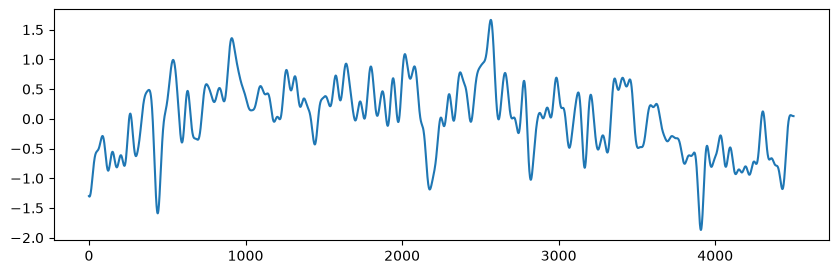

In [19]:
import matplotlib.pyplot as plt

# the first simulation, z-scored
plt.figure(figsize=(10, 3))
plt.plot(sim_lp[0])
plt.show()

In [20]:
from neurodsp.spectral import compute_spectrum
freqs, psd = compute_spectrum(dpl[0], fs_sim, method="welch")
band = (freqs >= 5) & (freqs <= 20)
print(freqs[band][psd[band].argmax()])

8.0


In [21]:
# relative differences from the real period and amplitude (comparing top simulations using amplitude/period then comparing it to held out features ptsym and rdsym)
period_diff = (sim_summary['period_ms'] - real_period_ms).abs() / real_period_ms #  computes how far the ratio is from 1
amp_diff = (sim_summary['amp'] - real_amp).abs() / real_amp

# total score (lower means closer)
sim_summary['score'] = period_diff + amp_diff

# simulated / mean and std - z score across features / optimization notebook 
# spectral event repository (in joneslab github) 

# the 5 closest simulations
print(sim_summary.sort_values('score').head(5))

    sim  period_ms       amp     rdsym     ptsym  burst_frac     score
24   40      92.50  2.065462  0.320388  0.607143    0.142857  0.064543
30   46      95.75  1.972578  0.388969  0.455524    0.380952  0.143971
28   44      95.00  1.596498  0.566102  0.413655    0.238095  0.311023
7    10      85.00  1.478486  0.625899  0.514706    0.142857  0.366059
8    12      91.50  1.273067  0.475914  0.548674    0.181818  0.422968


In [22]:
print(real_rdsym)
print(real_ptsym)

#  difference between best (most optimal) simulation and real eeg data (pre-optimization)
best_sim = sim_summary[sim_summary['sim'] == 40] # row 24
rdsym_40 = best_sim['rdsym'].iloc[0]
ptsym_40 = best_sim['ptsym'].iloc[0]

print(rdsym_40)
print(ptsym_40)

rdsym_diff = abs(real_rdsym - rdsym_40)
ptsym_diff = abs(real_ptsym - ptsym_40)
print(rdsym_diff)
print(ptsym_diff)

0.49019607843137253
0.5102040816326531
0.32038834951456313
0.6071428571428571
0.1698077289168094
0.09693877551020402


In [24]:
# optimization - using HNN optimization tutorial 

from hnn_core.optimization import Optimizer
from urllib.request import urlretrieve
import os.path as op

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

In [25]:
import hnn_core
from hnn_core import (MPIBackend, neymotin_2020_model, simulate_dipole,
                      read_dipole)
from hnn_core.viz import plot_dipole

hnn_core_root = op.join(op.dirname(hnn_core.__file__))

# The number of cores may need modifying depending on your current machine.
n_procs = 10

In [36]:
# load in experimental data or dipole (single-subject eeg data)

# pick one epoch and one channel from data (epochs x channels x time)
sig = ec_data[subj][0, ALL_CHANNELS_26.index('Oz')]

# convert to ms from Hz 
times = np.arange(len(sig)) / fs * 1000

np.savetxt('eeg_restEC.txt', np.column_stack([times, sig]))

dipole_experimental = read_dipole('eeg_restEC.txt')

# load in simulated data
best_idx = 40
sim_times = np.arange(dpl.shape[1]) * dt   # ms


In [38]:
# z scoring both the experimental and simulated data 

# exp data
sig = (sig - sig.mean()) / sig.std()

# sim data 
sim_best = (dpl[best_idx] - dpl[best_idx].mean()) / dpl[best_idx].std()


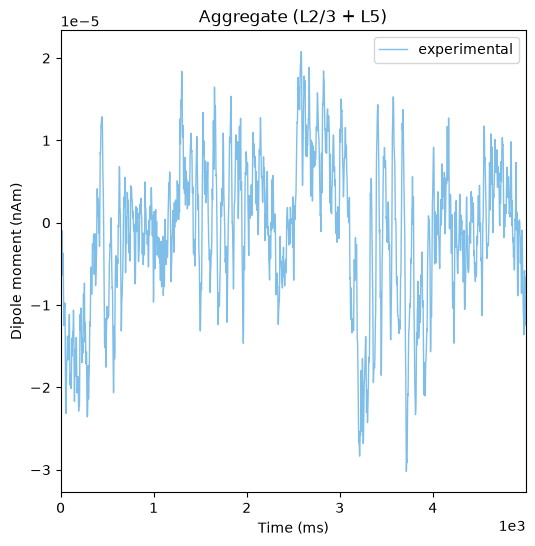

In [39]:
# Plotting exp. data
fig, ax = plt.subplots(figsize=(6, 6))
dipole_experimental.plot(ax=ax, layer='agg', show=False,
                         color='tab:blue')
ax.legend(['experimental'])

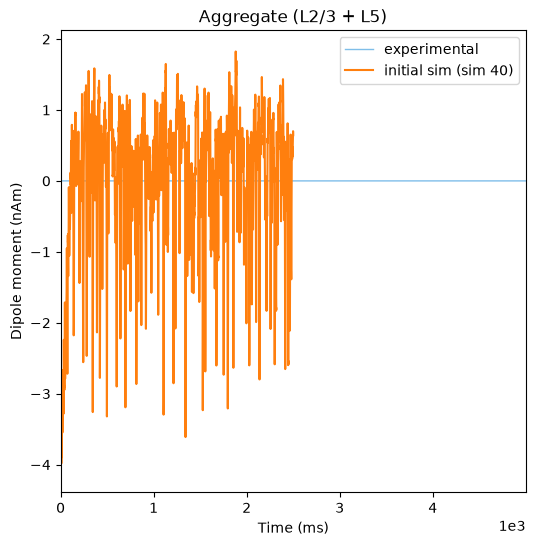

In [41]:
# plotting both sim. and exp. data
fig, ax = plt.subplots(figsize=(6, 6))
dipole_experimental.plot(ax=ax, layer='agg', show=False, color='tab:blue')
ax.plot(sim_times, sim_best, color='tab:orange')
ax.legend(['experimental', 'initial sim (sim 40)'])

In [30]:
print(sig.min(), sig.max(), sig.std())
print(dpl[best_idx].min(), dpl[best_idx].max(), dpl[best_idx].std())

-3.0209459112924834e-05 2.0796483401583203e-05 9.015654268723278e-06
-0.0011144943351342467 0.10151612857404108 0.01733325138889388
